# Titanic Passenger Survival Study
**Data Science Internship Project — CODETECH Technologies**

## Objective
Analyze the Titanic passenger dataset to understand which passenger characteristics were associated with survival, then build a simple machine-learning model to predict survival.

### Questions explored
- What proportion of passengers survived?
- How did survival vary by passenger class, sex, and age?
- Which features are most useful for predicting survival?

> **Dataset note:** This notebook first looks for `train.csv` in the project folder. If it is not present, it downloads a public copy of the Titanic dataset. For a formal submission, keep the dataset source noted in your report and verify your internship's data-source requirements.


In [ ]:
# 1. Import libraries
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)


In [ ]:
# 2. Load the dataset
# Preferred: place the official Kaggle Titanic train.csv file beside this notebook.
DATA_PATH = "train.csv"

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded local dataset: {DATA_PATH}")
else:
    dataset_url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    try:
        df = pd.read_csv(dataset_url)
        print("Loaded public Titanic dataset from a GitHub-hosted copy.")
    except Exception as exc:
        raise RuntimeError(
            "Dataset could not be loaded. Download Titanic train.csv from Kaggle, "
            "place it beside this notebook, and run again."
        ) from exc

print("Dataset shape:", df.shape)
display(df.head())


Loaded public Titanic dataset from a GitHub-hosted copy.
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Understand and clean the data
The target column is `Survived`: `0` means did not survive and `1` means survived. We inspect data types, missing values, and duplicate rows before analysis.

In [ ]:
print("Column names:", df.columns.tolist())
print("\\nData types and non-null counts:")
display(df.info())
print("\\nMissing values by column:")
display(df.isnull().sum().sort_values(ascending=False))
print("\\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)


Column names: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None

\nMissing values by column:


,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


\nDuplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 4. Exploratory Data Analysis (EDA)
The charts below summarize survival overall and compare survival rates across selected passenger groups.

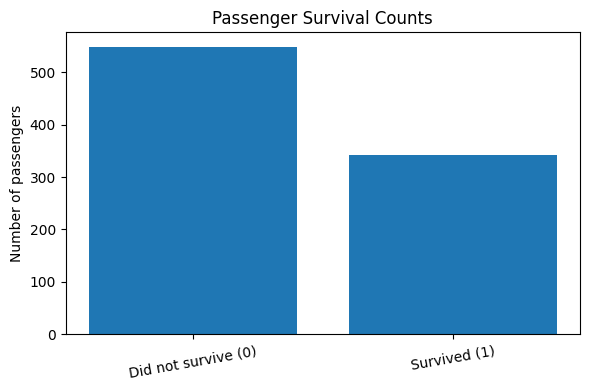

Overall survival rate: 38.4%


In [ ]:
# Overall survival distribution
survival_counts = df["Survived"].value_counts().sort_index()
labels = ["Did not survive (0)", "Survived (1)"]
plt.figure(figsize=(6, 4))
plt.bar(labels, [survival_counts.get(0, 0), survival_counts.get(1, 0)])
plt.title("Passenger Survival Counts")
plt.ylabel("Number of passengers")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

print("Overall survival rate: {:.1f}%".format(df["Survived"].mean() * 100))


,Survival rate (%)
Sex,
female,74.2
male,18.9


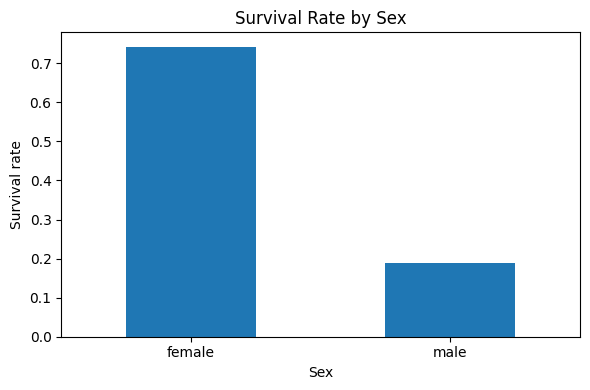

,Survival rate (%)
Pclass,
1,63.0
2,47.3
3,24.2


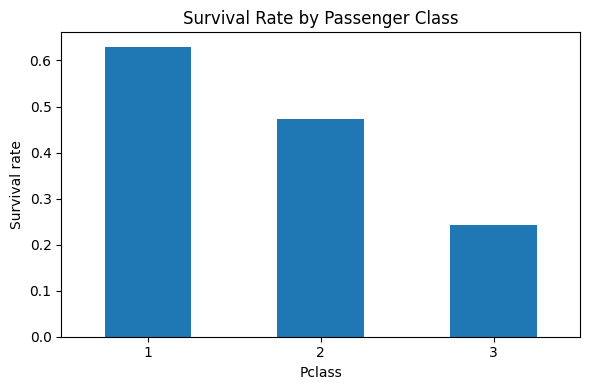

In [ ]:
# Survival rate by sex, if the column is available
if "Sex" in df.columns:
    sex_survival = df.groupby("Sex", dropna=False)["Survived"].mean().sort_values(ascending=False)
    display((sex_survival * 100).round(1).rename("Survival rate (%)").to_frame())
    sex_survival.plot(kind="bar", figsize=(6, 4), title="Survival Rate by Sex", ylabel="Survival rate")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Survival rate by passenger class
if "Pclass" in df.columns:
    class_survival = df.groupby("Pclass")["Survived"].mean()
    display((class_survival * 100).round(1).rename("Survival rate (%)").to_frame())
    class_survival.plot(kind="bar", figsize=(6, 4), title="Survival Rate by Passenger Class", ylabel="Survival rate")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


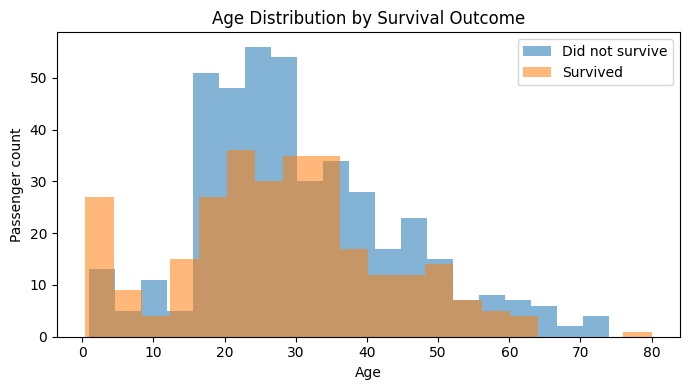

In [ ]:
# Age distribution for survivors and non-survivors
if "Age" in df.columns:
    plt.figure(figsize=(7, 4))
    for outcome, label in [(0, "Did not survive"), (1, "Survived")]:
        values = df.loc[df["Survived"] == outcome, "Age"].dropna()
        plt.hist(values, bins=20, alpha=0.55, label=label)
    plt.title("Age Distribution by Survival Outcome")
    plt.xlabel("Age")
    plt.ylabel("Passenger count")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 5. Prepare features for machine learning
We use a small set of passenger attributes and exclude identifiers and post-outcome leakage. Missing numeric values are filled with the median; missing categorical values are filled with the most frequent value. Categorical variables are one-hot encoded.

In [ ]:
# Select features that commonly exist in Titanic datasets
candidate_features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
features = [col for col in candidate_features if col in df.columns]
if not features:
    raise ValueError("None of the expected feature columns were found in the dataset.")

X = df[features].copy()
y = df["Survived"].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Features used:", features)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Features used: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Training rows: 712
Testing rows: 179


## 6. Train a Random Forest classifier
A Random Forest combines multiple decision trees. We evaluate it on a held-out test set. The test metrics estimate performance on unseen data, but results can vary with the dataset and split.

In [ ]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0)
}
display(pd.DataFrame(metrics.items(), columns=["Metric", "Score"]).set_index("Metric").round(3))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


,Score
Metric,
Accuracy,0.816
Precision,0.800
Recall,0.696
F1-score,0.744


\nClassification report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



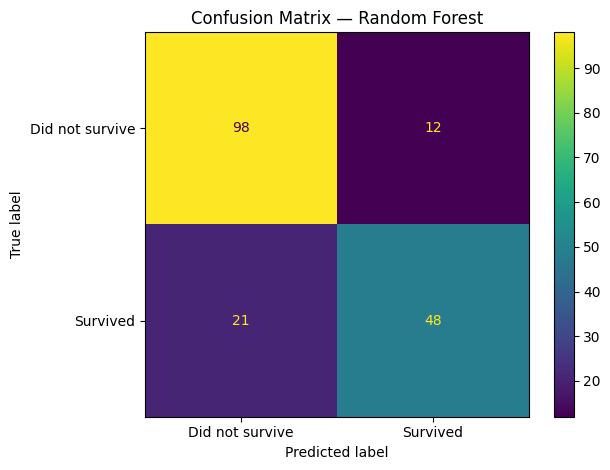

In [ ]:
# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Did not survive", "Survived"],
    values_format="d"
)
plt.title("Confusion Matrix — Random Forest")
plt.tight_layout()
plt.show()


## 7. Feature importance
Feature importance indicates which transformed inputs the Random Forest relied on most in this fitted model. It describes model behavior, not cause and effect.

,Importance
num__Fare,0.262349
num__Age,0.255547
cat__Sex_female,0.151049
cat__Sex_male,0.132984
num__Pclass,0.078837
num__SibSp,0.047288
num__Parch,0.035901
cat__Embarked_S,0.016616
cat__Embarked_C,0.012409
cat__Embarked_Q,0.007021


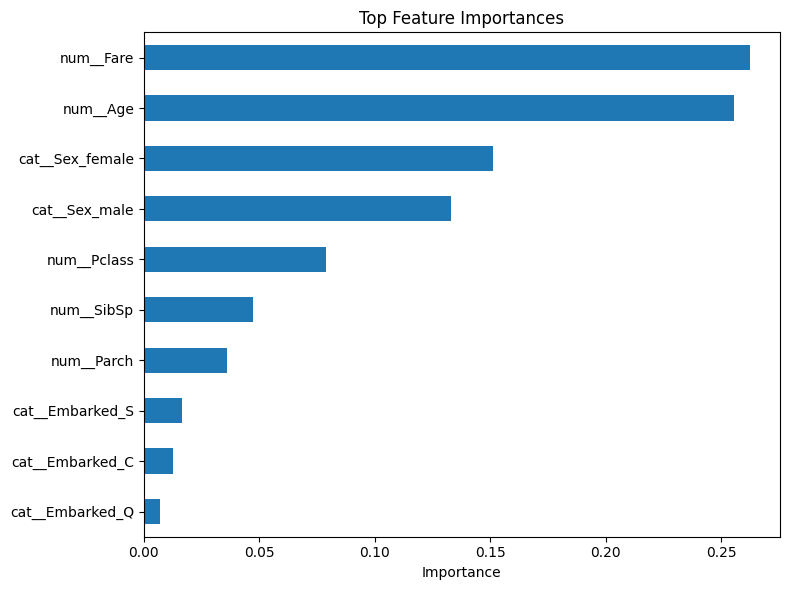

In [ ]:
# Get transformed feature names and model importances
fitted_preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

try:
    transformed_names = fitted_preprocessor.get_feature_names_out()
    importances = pd.Series(classifier.feature_importances_, index=transformed_names)
    importances = importances.sort_values(ascending=False).head(15)
    display(importances.rename("Importance").to_frame())
    importances.sort_values().plot(kind="barh", figsize=(8, 6), title="Top Feature Importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Could not display feature names for this environment:", exc)
